# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: LogisticRegression
Test: (36, 13)


## 2. Evaluación final

Accuracy test: 0.9722
F1 macro test: 0.9710
Accuracy CV (train): 0.9791 +/- 0.0277

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        12
           1      0.933     1.000     0.966        14
           2      1.000     0.900     0.947        10

    accuracy                          0.972        36
   macro avg      0.978     0.967     0.971        36
weighted avg      0.974     0.972     0.972        36



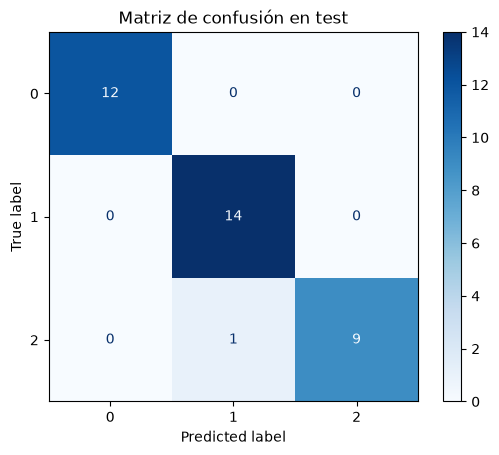

In [4]:
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="macro")
print(f"Accuracy test: {acc:.4f}")
print(f"F1 macro test: {f1:.4f}")
print(f"Accuracy CV (train): {training_metadata['cv_accuracy']:.4f} +/- {training_metadata['cv_std']:.4f}\n")
print(classification_report(y_test, y_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matriz de confusión en test")
plt.show()

**Análisis:**

> El desempeño es coherente con la validación cruzada: accuracy de 0.972 en test frente a 0.979 +/- 0.028 en CV, una diferencia dentro de una desviación estándar. La matriz de confusión muestra un único error sobre 36 muestras: un vino de clase 2 predicho como clase 1 (recall de la clase 2 de 0.90, precisión de la clase 1 de 0.933). La clase 0 se clasifica sin errores. No hay evidencia de sobreajuste al conjunto de test: el modelo no cayó respecto a CV, aunque con solo 36 muestras cada error mueve unos 2.8 puntos de accuracy, así que la estimación es ruidosa. Además, la predicción por lotes muestra casos con probabilidades poco seguras (por ejemplo, 0.54 frente a 0.45 entre las clases 1 y 2 en el segundo registro), lo que apunta a que la frontera entre esas dos clases es la zona delicada.

## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    missing = [c for c in feature_columns if c not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")
    X = records[feature_columns]  # ordena como en el entrenamiento e ignora columnas extra
    out = pd.DataFrame({"prediction": model.predict(X)}, index=records.index)
    proba = model.predict_proba(X)
    for cls, col in zip(model.classes_, proba.T):
        out[f"proba_class_{cls}"] = col.round(4)
    return out

# Prueba de la validación del esquema
try:
    predict(X_test.drop(columns=["alcohol"]).iloc[:2])
except ValueError as e:
    print("Validación correcta ->", e)

Validación correcta -> Faltan columnas requeridas: ['alcohol']


## 4. Predicción por lotes

In [6]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

# Se desordenan las columnas a propósito para comprobar que predict las reordena
batch = predict(new_records[new_records.columns[::-1]])
batch.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
batch

,prediction,proba_class_0,proba_class_1,proba_class_2
0,0,0.9997,0.0003,0.0000
1,1,0.0071,0.5404,0.4525
2,0,0.9920,0.0077,0.0003
3,1,0.2900,0.7075,0.0026
4,1,0.0330,0.9623,0.0047


## 5. Reporte final

In [7]:
test_metrics = {
    "model": training_metadata["champion"],
    "accuracy": float(acc),
    "f1_macro": float(f1),
    "n_test": int(len(X_test)),
}
(REPORTS_DIR / "test_metrics.json").write_text(json.dumps(test_metrics, indent=2), encoding="utf-8")
print(json.dumps(test_metrics, indent=2))

{
  "model": "LogisticRegression",
  "accuracy": 0.9722222222222222,
  "f1_macro": 0.9709618874773139,
  "n_test": 36
}


In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | Regresión logística (C=1) con StandardScaler |
| Accuracy CV | 0.9791 +/- 0.0277 |
| Accuracy test | 0.9722 |
| F1 macro test | 0.9710 |
| Clases más confundidas | Clase 2 predicha como clase 1 (1 caso) |
| Principal limitación | Test de solo 36 muestras (cada error pesa 2.8 puntos) y dataset pequeño de un solo origen; la métrica es poco precisa y no se probó con datos nuevos reales |

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.